In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, GlobalMaxPool1D, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import string

In [2]:
#Loading Data
train_df = pd.read_csv("liar_dataset/train.tsv", sep='\t', header=None)
val_df = pd.read_csv("liar_dataset/valid.tsv", sep='\t', header=None)
test_df = pd.read_csv("liar_dataset/test.tsv", sep='\t', header=None)

In [3]:
# Check class distribution for each split
print("Train Set Label Distribution:\n", train_df[1].value_counts())
print("\nValidation Set Label Distribution:\n", val_df[1].value_counts())
print("\nTest Set Label Distribution:\n", test_df[1].value_counts())

Train Set Label Distribution:
 1
half-true      2114
false          1995
mostly-true    1962
true           1676
barely-true    1654
pants-fire      839
Name: count, dtype: int64

Validation Set Label Distribution:
 1
false          263
mostly-true    251
half-true      248
barely-true    237
true           169
pants-fire     116
Name: count, dtype: int64

Test Set Label Distribution:
 1
half-true      265
false          249
mostly-true    241
barely-true    212
true           208
pants-fire      92
Name: count, dtype: int64


In [4]:
# Function to concatenate statement with relevant metadata fields
def combine_text(df):
    df = df.fillna('')
    combined = (
        df[2].astype(str) + " " +  # statement
        df[3].astype(str) + " " +  # subject(s)
        df[4].astype(str) + " " +  # speaker
        df[5].astype(str) + " " +  # speaker's job title
        df[6].astype(str) + " " +  # state info
        df[7].astype(str) + " " +  # party affiliation
        df[13].astype(str)         # context (venue/location)
    )
    return combined.tolist()

In [5]:
# Create combined text inputs
train_statements = combine_text(train_df)
val_statements = combine_text(val_df)
test_statements = combine_text(test_df)

In [6]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /Users/ganpat-
[nltk_data]     patel/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/ganpat-
[nltk_data]     patel/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/ganpat-
[nltk_data]     patel/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [7]:
# Function to preprocess text
def preprocess_text(text):
    # Tokenization
    tokens = word_tokenize(text)
    
    # Lowercasing
    tokens = [word.lower() for word in tokens]
    
    # Remove punctuation
    tokens = [word for word in tokens if word not in string.punctuation]
    
    # Remove stop words
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]
    
    # Lemmatization
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    # Join tokens back into a single string
    cleaned_text = ' '.join(tokens)
    
    return cleaned_text

In [8]:
# Apply preprocessing to combined text inputs
train_statements = [preprocess_text(statement) for statement in train_statements]
val_statements = [preprocess_text(statement) for statement in val_statements]
test_statements = [preprocess_text(statement) for statement in test_statements]

In [9]:
# Map string labels to integers (same as before)
label_map = {
    "false": 0,
    "barely-true": 1,
    "half-true": 2,
    "mostly-true": 3,
    "true": 4,
    "pants-fire": 5
}

In [10]:
def map_labels(label_list):
    mapped = []
    for label in label_list:
        label = label.lower().replace(" ", "-")
        mapped.append(label_map.get(label, 0))
    return mapped

In [11]:
train_labels = map_labels(train_df[1].tolist())
val_labels = map_labels(val_df[1].tolist())
test_labels = map_labels(test_df[1].tolist())

In [12]:
# Tokenize and pad sequences
max_words = 100000
max_sequence_length = 350
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(train_statements)

In [13]:
print("Converting training statements to sequences...")
train_sequences = [tokenizer.texts_to_sequences([text])[0] for text in tqdm(train_statements, desc="Training Sequences")]
print("Converting validation statements to sequences...")
val_sequences = [tokenizer.texts_to_sequences([text])[0] for text in tqdm(val_statements, desc="Validation Sequences")]
print("Converting test statements to sequences...")
test_sequences = [tokenizer.texts_to_sequences([text])[0] for text in tqdm(test_statements, desc="Test Sequences")]

Converting training statements to sequences...


Training Sequences: 100%|██████████████| 10240/10240 [00:00<00:00, 63702.57it/s]


Converting validation statements to sequences...


Validation Sequences: 100%|██████████████| 1284/1284 [00:00<00:00, 65094.78it/s]


Converting test statements to sequences...


Test Sequences: 100%|████████████████████| 1267/1267 [00:00<00:00, 64425.27it/s]


In [14]:
train_data_padded = pad_sequences(train_sequences, maxlen=max_sequence_length, padding="post", truncating="post")
val_data_padded = pad_sequences(val_sequences, maxlen=max_sequence_length, padding="post", truncating="post")
test_data_padded = pad_sequences(test_sequences, maxlen=max_sequence_length, padding="post", truncating="post")

In [15]:
# One-hot encode labels
num_classes = 6
train_labels_cat = to_categorical(train_labels, num_classes=num_classes)
val_labels_cat = to_categorical(val_labels, num_classes=num_classes)
test_labels_cat = to_categorical(test_labels, num_classes=num_classes)

In [16]:
# Load GloVe embeddings with progress bar
embedding_dim = 100
glove_dir = 'glove.6B.100d.txt'
embeddings_index = {}
print("Loading GloVe embeddings...")
with open(glove_dir, encoding='utf8') as f:
    total_lines = sum(1 for _ in open(glove_dir, encoding='utf8'))
    for line in tqdm(f, total=total_lines, desc="Reading GloVe File"):
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

word_index = tokenizer.word_index
num_words = min(max_words, len(word_index) + 1)
embedding_matrix = np.zeros((num_words, embedding_dim))
for word, i in word_index.items():
    if i < max_words:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

Loading GloVe embeddings...


Reading GloVe File: 100%|████████████| 400000/400000 [00:06<00:00, 58074.72it/s]


In [17]:
model = Sequential()
model.add(Embedding(num_words, embedding_dim, weights=[embedding_matrix], trainable=False))
model.add((LSTM(128, return_sequences=True)))  # Increased to 128 units
model.add(GlobalMaxPool1D())
model.add(Dropout(0.3))  # Slightly higher dropout
model.add(Dense(100, activation="relu"))  # Increased units
model.add(Dropout(0.3))
model.add(Dense(50, activation="relu"))  # Additional dense layer
model.add(Dense(num_classes, activation="softmax"))

In [18]:
# Compile with all relevant metrics for multi-class classification
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',                          # Standard accuracy
        tf.keras.metrics.TopKCategoricalAccuracy(k=3, name='top_3_accuracy'),  # Top-3 accuracy
        tf.keras.metrics.Precision(name='precision'),  # Weighted precision
        tf.keras.metrics.Recall(name='recall'),        # Weighted recall
        tf.keras.metrics.F1Score(name='f1_score'),     # F1 score (harmonic mean of precision and recall)
        tf.keras.metrics.AUC(name='auc'),              # Area under ROC curve
    ]
)

In [19]:
# Train the model
batch_size = 128
epochs = 10
print("Training model...")
history = model.fit(train_data_padded, train_labels_cat, batch_size=batch_size, epochs=epochs, validation_data=(val_data_padded, val_labels_cat), verbose=1)

Training model...
Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 61s 741ms/step - accuracy: 0.1983 - auc: 0.5691 - f1_score: 0.1519 - loss: 1.7699 - precision: 0.0000e+00 - recall: 0.0000e+00 - top_3_accuracy: 0.5777 - val_accuracy: 0.2570 - val_auc: 0.6150 - val_f1_score: 0.1517 - val_loss: 1.7268 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_top_3_accuracy: 0.6332
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 61s 757ms/step - accuracy: 0.2336 - auc: 0.6061 - f1_score: 0.1639 - loss: 1.7339 - precision: 0.0000e+00 - recall: 0.0000e+00 - top_3_accuracy: 0.6240 - val_accuracy: 0.2586 - val_auc: 0.6495 - val_f1_score: 0.1491 - val_loss: 1.6918 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_top_3_accuracy: 0.6674
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 61s 765ms/step - accuracy: 0.2379 - auc: 0.6216 - f1_score: 0.1871 - loss: 1.7153 - precision: 0.2174 - recall: 8.4825e-05 - top_3_accuracy: 0.6362 - val_accuracy: 0.2640 - val_auc: 0.6648 - val_f1_score: 0.2452 - val_loss: 1.6647 - v

In [21]:
# Predict and compute metrics
print("Predicting on test set...")
y_pred = model.predict(test_data_padded, batch_size=batch_size, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(test_labels_cat, axis=1)

Predicting on test set...


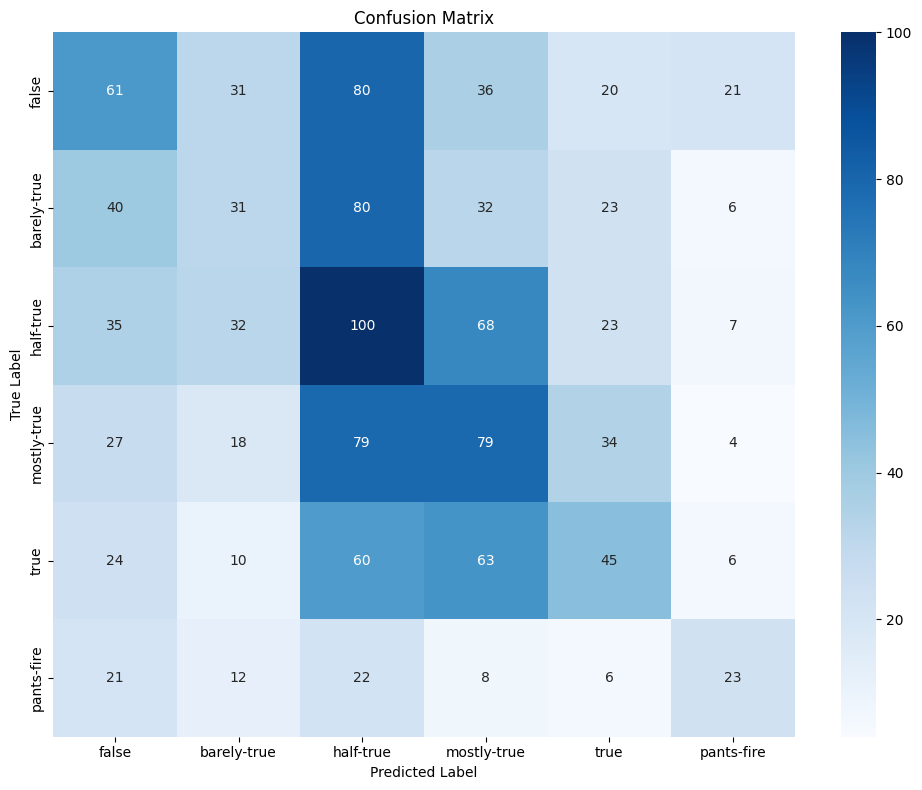

In [22]:
# Confusion matrix plot
class_names = ['false', 'barely-true', 'half-true', 'mostly-true', 'true', 'pants-fire']
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

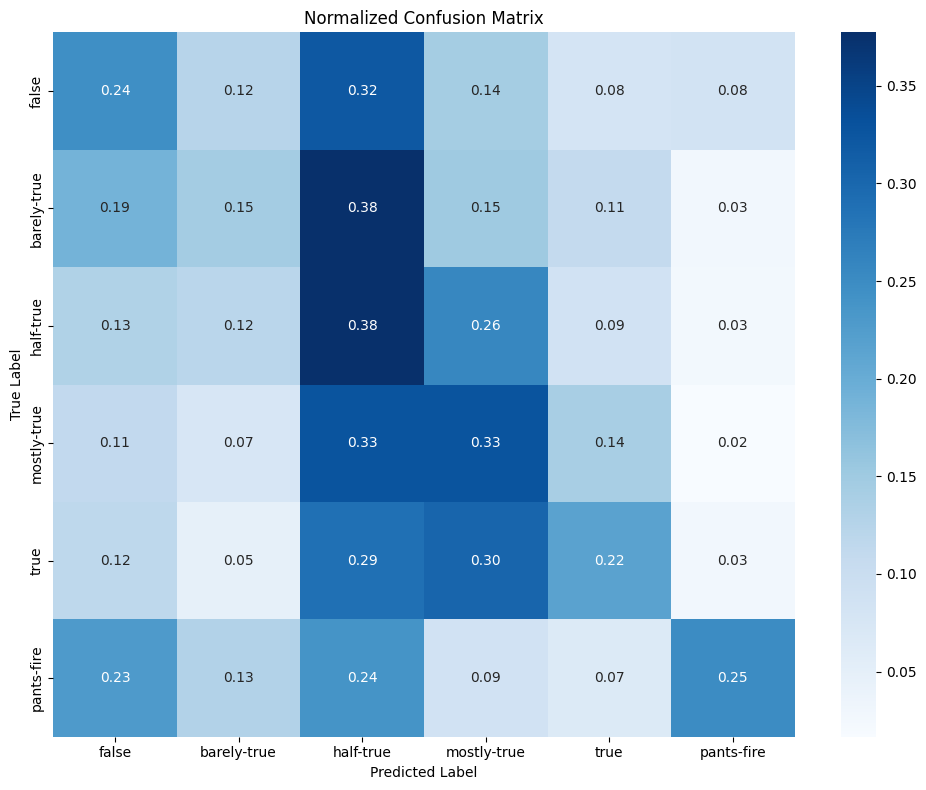

In [23]:
# Normalized Confusion matrix plot
class_names = ['false', 'barely-true', 'half-true', 'mostly-true', 'true', 'pants-fire']
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Normalize the confusion matrix by rows (true labels)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot normalized confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Normalized Confusion Matrix')
plt.tight_layout()
plt.show()

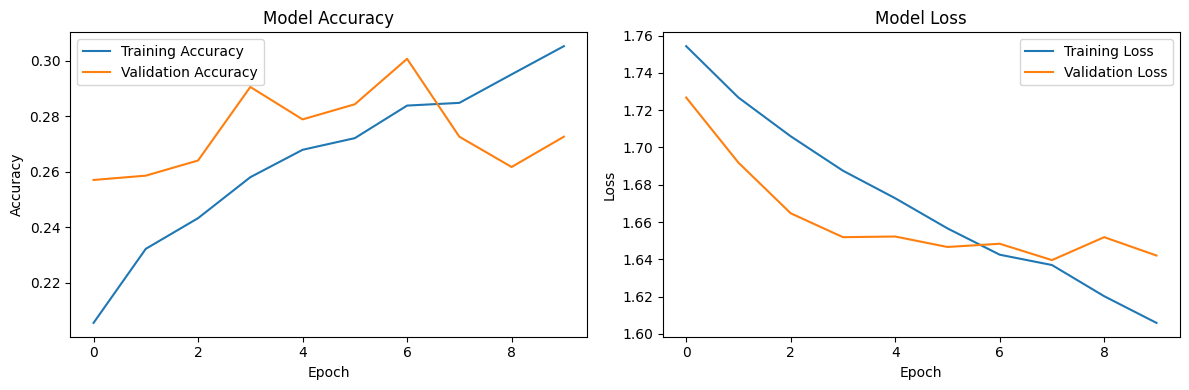

In [24]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()